# 01 · Data Preparation
**RedactNER: Local PII Redaction for Word Documents**

This notebook builds the training, development and test sets used to fine-tune and compare the PII
token classifiers. It runs in the project environment or on Google Colab.

| Role | Dataset | Content | Licence |
|---|---|---|---|
| Training, Development and Test | `nvidia/Nemotron-PII` | Document-style synthetic PII such as resumes, forms and reports | CC BY 4.0 |
| Training, Development and Test | `ai4privacy/pii-masking-openpii-1.5m` (English rows) | Short synthetic emails, forms and chat messages | CC BY 4.0 |
| Training, Development and Test | `gretelai/synthetic_pii_finance_multilingual` (English rows) | Long synthetic financial documents such as agreements, statements and claim forms | Apache 2.0 |
| Test Only | Text Anonymization Benchmark (TAB), test split | Real court judgments of the European Court of Human Rights, annotated by legal experts | MIT |

Every source is mapped onto a single taxonomy of 13 categories: Person, Email, Phone, Address,
Location, Date, ID Number, Financial, Username, Credential, IP Address, URL and Organisation.
Character offsets are validated and span conventions are harmonised. Test documents that duplicate or
nearly duplicate a training document are removed. The training set is then augmented with Australian
formats, upper- and lower-case names and form layouts.

TAB is never used for training or tuning. It is the only test set written by people rather than
generated, so it measures how well the models transfer to real documents.

In [1]:
# documents drawn from each source and split, plus the augmentation and de-duplication settings
N_NEMOTRON_TRAIN = 30000
N_NEMOTRON_DEV = 1500
N_NEMOTRON_TEST = 1000
N_AI4P_TRAIN = 20000
N_AI4P_DEV = 750
N_AI4P_TEST = 1000
N_GRETEL_TRAIN = 10000
N_GRETEL_DEV = 500
N_GRETEL_TEST = 1000
N_FORMS = 3000             # synthetic form documents added to the training set
REPLACE_FRACTION = 0.20    # training documents whose values are replaced with Australian-format values
CASE_FRACTION = 0.08       # training documents whose person names are written in upper or lower case
NEAR_DUP_JACCARD = 0.8     # MinHash similarity at which a test document counts as a near-duplicate
SEED = 42
PROJECT_DIR = ".."  # notebooks/ lives one level below the project root

## 0. Setup
On Google Colab this cell installs the additional packages required. Locally, all dependencies come
from the project environment created with `uv sync`.

In [2]:
import subprocess
import sys

# on Google Colab, install the extra packages and use the cloned repository as the project root
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets>=3.0", "datasketch", "faker",
                    "matplotlib", "pandas"], check=True)
    PROJECT_DIR = "/content/redactner"

import ast
import hashlib
import json
import random
import re
import time
import urllib.request
from collections import Counter, defaultdict
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from datasketch import MinHash, MinHashLSH
from faker import Faker

# folders for the processed splits, raw downloads and results
ROOT = Path(PROJECT_DIR).resolve()
DATA_OUT = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw"
FIG_DIR = ROOT / "results"
for folder in (DATA_OUT, RAW, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
rng = random.Random(SEED)  # one seeded generator makes every sample and augmentation reproducible

## 1. Taxonomy and Label Mappings
Source labels outside the taxonomy, such as job titles, gender, age, sensitive attributes and times,
are mapped to `None` and treated as non-PII (`O`).

In [3]:
# the 13 categories and their BIO tags: O plus a B- and an I- tag per category, 27 labels
LABELS = ["PERSON", "EMAIL", "PHONE", "ADDRESS", "LOCATION", "DATE", "ID_NUMBER", "FINANCIAL",
          "USERNAME", "CREDENTIAL", "IP_ADDRESS", "URL", "ORGANIZATION"]
BIO_LABELS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
CATEGORY_NAMES = {"PERSON": "Person", "EMAIL": "Email", "PHONE": "Phone", "ADDRESS": "Address",
                  "LOCATION": "Location", "DATE": "Date", "ID_NUMBER": "ID Number", "FINANCIAL": "Financial",
                  "USERNAME": "Username", "CREDENTIAL": "Credential", "IP_ADDRESS": "IP Address", "URL": "URL",
                  "ORGANIZATION": "Organisation"}
SPLIT_NAMES = {"train": "Training", "dev": "Development", "test_nemotron": "Nemotron-PII Test",
               "test_ai4privacy": "ai4privacy Test", "test_gretel": "Gretel Finance Test", "test_tab": "TAB Test"}

# source label -> category; None marks a label outside the taxonomy, which becomes O
NEMOTRON_MAP = {
    "first_name": "PERSON", "last_name": "PERSON", "name": "PERSON", "middle_name": "PERSON",
    "email": "EMAIL",
    "phone_number": "PHONE", "fax_number": "PHONE",
    "street_address": "ADDRESS", "postcode": "ADDRESS",
    "city": "LOCATION", "county": "LOCATION", "state": "LOCATION", "coordinate": "LOCATION",
    "date": "DATE", "date_of_birth": "DATE", "date_time": "DATE",
    "ssn": "ID_NUMBER", "national_id": "ID_NUMBER", "tax_id": "ID_NUMBER",
    "medical_record_number": "ID_NUMBER", "health_plan_beneficiary_number": "ID_NUMBER",
    "customer_id": "ID_NUMBER", "employee_id": "ID_NUMBER", "unique_id": "ID_NUMBER",
    "certificate_license_number": "ID_NUMBER", "license_plate": "ID_NUMBER",
    "vehicle_identifier": "ID_NUMBER", "device_identifier": "ID_NUMBER", "biometric_identifier": "ID_NUMBER",
    "account_number": "FINANCIAL", "bank_routing_number": "FINANCIAL", "swift_bic": "FINANCIAL",
    "credit_debit_card": "FINANCIAL",
    "cvv": "CREDENTIAL", "pin": "CREDENTIAL", "password": "CREDENTIAL", "api_key": "CREDENTIAL",
    "http_cookie": "CREDENTIAL",
    "ipv4": "IP_ADDRESS", "ipv6": "IP_ADDRESS", "mac_address": "IP_ADDRESS",
    "url": "URL",
    "user_name": "USERNAME",
    "company_name": "ORGANIZATION",
    # quasi-identifiers and sensitive attributes outside the taxonomy
    "age": None, "gender": None, "race_ethnicity": None, "sexuality": None, "religious_belief": None,
    "political_view": None, "marital_status": None, "nationality": None, "education_level": None,
    "occupation": None, "employment_status": None, "language": None, "blood_type": None,
    "country": None, "time": None,
}

AI4P_MAP = {
    "GIVENNAME": "PERSON", "SURNAME": "PERSON", "TITLE": None,
    "EMAIL": "EMAIL", "TELEPHONENUM": "PHONE",
    "STREET": "ADDRESS", "BUILDINGNUM": "ADDRESS", "ZIPCODE": "ADDRESS", "CITY": "LOCATION",
    "DATE": "DATE", "TIME": None, "AGE": None, "GENDER": None, "SEX": None,
    "IDCARDNUM": "ID_NUMBER", "PASSPORTNUM": "ID_NUMBER", "DRIVERLICENSENUM": "ID_NUMBER",
    "SOCIALNUM": "ID_NUMBER", "TAXNUM": "ID_NUMBER",
    "CREDITCARDNUMBER": "FINANCIAL", "USERNAME": "USERNAME", "BANKNAME": None,
    # rare labels found in a small number of English rows
    "ORGANISATION": "ORGANIZATION", "URL": "URL", "IPV4": "IP_ADDRESS", "IPV6": "IP_ADDRESS",
    "COUNTRY": None, "CURRENCY": None, "AMOUNT": None, "SALARY": None, "ALLERGIES": None, "TIMEZONE": None,
    "WEIGHT": None, "HEIGHT": None,
}

GRETEL_MAP = {
    "name": "PERSON", "first_name": "PERSON", "last_name": "PERSON",
    "email": "EMAIL", "phone_number": "PHONE",
    "street_address": "ADDRESS", "local_latlng": "LOCATION",
    "date": "DATE", "date_of_birth": "DATE", "date_time": "DATE", "time": None,
    "company": "ORGANIZATION",
    "ssn": "ID_NUMBER", "driver_license_number": "ID_NUMBER", "passport_number": "ID_NUMBER",
    "customer_id": "ID_NUMBER", "employee_id": "ID_NUMBER",
    "account_pin": "CREDENTIAL", "password": "CREDENTIAL", "api_key": "CREDENTIAL",
    "credit_card_security_code": "CREDENTIAL",
    "bban": "FINANCIAL", "iban": "FINANCIAL", "swift_bic_code": "FINANCIAL",
    "bank_routing_number": "FINANCIAL", "credit_card_number": "FINANCIAL",
    "ipv4": "IP_ADDRESS", "ipv6": "IP_ADDRESS",
    "user_name": "USERNAME",
}

# TAB annotates entities with one of eight types. Demographic attributes, quantities and miscellaneous
# entities fall outside the taxonomy and are not scored.
TAB_MAP = {"PERSON": "PERSON", "CODE": "ID_NUMBER", "LOC": "LOCATION", "ORG": "ORGANIZATION",
           "DATETIME": "DATE", "DEM": None, "QUANTITY": None, "MISC": None}

unknown_labels: Counter = Counter()


def map_label(mapping: dict, raw: str, source: str):
    """Map a source label to its category, ignoring case, and count labels without a mapping."""
    if raw in mapping:
        return mapping[raw]
    key = raw.lower() if source != "ai4privacy" else raw.upper()
    if key in mapping:
        return mapping[key]
    unknown_labels[(source, raw)] += 1
    return None

## 2. Span Harmonisation
* Offsets are validated against the text and, where the source provides it, against the stored value.
* Leading and trailing whitespace, possessive *'s* and trailing punctuation are trimmed.
* Overlapping spans are resolved in favour of the longest span.
* Adjacent spans of the same category separated only by whitespace are merged, for example
  `first_name` and `last_name` into one Person span, or `BUILDINGNUM` and `STREET` into one Address span.

In [4]:
TRAIL_PUNCT = ",;:"
POSSESSIVE = re.compile(r"(?:'s|’s)$")


def clean_span(text: str, start: int, end: int, label: str):
    """Trim spaces, trailing punctuation and a possessive 's, so every source marks boundaries alike."""
    while start < end and text[start].isspace():
        start += 1
    while end > start and (text[end - 1].isspace() or text[end - 1] in TRAIL_PUNCT):
        end -= 1
    if label in ("EMAIL", "URL", "PERSON") and end > start and text[end - 1] == ".":
        end -= 1
    if label == "PERSON":
        m = POSSESSIVE.search(text[start:end])
        if m:
            end -= len(m.group(0))
    return (start, end) if end > start else None


def harmonise(text: str, raw_spans: list[tuple[int, int, str]]) -> list[list]:
    """Clean one document's spans, keep the longest of overlapping spans and merge neighbouring ones."""
    spans = []
    for s, e, lab in raw_spans:
        c = clean_span(text, s, e, lab)
        if c:
            spans.append((c[0], c[1], lab))
    # overlap resolution: longest first
    kept: list[tuple[int, int, str]] = []
    for s, e, lab in sorted(spans, key=lambda x: (-(x[1] - x[0]), x[0])):
        if all(e <= ks or s >= ke for ks, ke, _ in kept):
            kept.append((s, e, lab))
    kept.sort()
    # merge adjacent same-type spans separated by whitespace (ADDRESS also by a comma)
    merged: list[list] = []
    for s, e, lab in kept:
        if merged and merged[-1][2] == lab:
            gap = text[merged[-1][1]:s]
            if (gap.strip() == "" and len(gap) <= 2) or (lab == "ADDRESS" and gap.strip() == "," and len(gap) <= 3):
                merged[-1][1] = e
                continue
        merged.append([s, e, lab])
    return merged


def text_key(text: str) -> str:
    """Hash of the lower-cased, whitespace-normalised text, used to find exact duplicates."""
    return hashlib.sha1(re.sub(r"\s+", " ", text.lower()).strip().encode()).hexdigest()

## 3. Load the Sources
For every source, a candidate pool larger than the target test size is drawn, so that the test sets keep
their size after duplicates are removed in Section 4.

In [5]:
t0 = time.time()
nemo = load_dataset("nvidia/Nemotron-PII")
print(nemo)
print("Features:", nemo["train"].features)

DatasetDict({
    train: Dataset({
        features: ['uid', 'domain', 'document_type', 'document_description', 'document_format', 'locale', 'text', 'spans', 'text_tagged'],
        num_rows: 100000
    })
    test: Dataset({
        features: ['uid', 'domain', 'document_type', 'document_description', 'document_format', 'locale', 'text', 'spans', 'text_tagged'],
        num_rows: 100000
    })
})
Features: {'uid': Value('string'), 'domain': Value('string'), 'document_type': Value('string'), 'document_description': Value('string'), 'document_format': Value('string'), 'locale': Value('string'), 'text': Value('string'), 'spans': Value('string'), 'text_tagged': Value('string')}


In [6]:
def parse_spans(value):
    """Read a span list stored either as JSON or as a Python literal."""
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return ast.literal_eval(value)
    return value or []


def nemotron_record(row, idx, split):
    """Convert a Nemotron-PII row to the shared record format, dropping spans that do not match the text."""
    text = row["text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["spans"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)):
            bad += 1
            continue
        if sp.get("text") is not None and text[s:e] != sp["text"]:
            bad += 1
            continue
        lab = map_label(NEMOTRON_MAP, sp["label"], "nemotron")
        if lab:
            raw.append((s, e, lab))
    return {
        "id": f"nemotron-{split}-{row.get('uid', idx)}",
        "source": "nemotron",
        "text": text,
        "spans": harmonise(text, raw),
        "meta": {"document_type": row.get("document_type"), "format": row.get("document_format"),
                 "locale": row.get("locale"), "domain": row.get("domain")},
        "_bad_spans": bad,
    }


# exact duplicates: test documents whose text also occurs in the training split are dropped
train_keys = {text_key(t) for t in nemo["train"]["text"]}
print(f"Unique training texts: {len(train_keys):,} of {len(nemo['train']):,}")

# random training and development sample
nemo_train_idx = list(range(len(nemo["train"])))
rng.shuffle(nemo_train_idx)
nemo_train_idx = nemo_train_idx[: N_NEMOTRON_TRAIN + N_NEMOTRON_DEV]

test_idx = [i for i, t in enumerate(nemo["test"]["text"]) if text_key(t) not in train_keys]
exact_removed = {"test_nemotron": len(nemo["test"]) - len(test_idx)}
rng.shuffle(test_idx)
test_idx = test_idx[: N_NEMOTRON_TEST + 500]  # spare candidates for near-duplicate removal

nemo_pool = [nemotron_record(nemo["train"][i], i, "train") for i in nemo_train_idx]
nemo_test = [nemotron_record(nemo["test"][i], i, "test") for i in test_idx]
nemo_train, nemo_dev = nemo_pool[:N_NEMOTRON_TRAIN], nemo_pool[N_NEMOTRON_TRAIN:]
print(f"Nemotron-PII: {len(nemo_train):,} training | {len(nemo_dev):,} development | {len(nemo_test):,} test candidates | "
      f"{exact_removed['test_nemotron']:,} test documents also in training | "
      f"{sum(r['_bad_spans'] for r in nemo_pool + nemo_test):,} invalid spans removed ({time.time() - t0:.0f} s)")

Unique training texts: 99,999 of 100,000


Nemotron-PII: 30,000 training | 1,500 development | 1,500 test candidates | 0 test documents also in training | 4,162 invalid spans removed (31 s)


The full OpenPII-1.5M corpus is streamed and the first English rows are kept. English accounts for
roughly 12 % of the corpus, so only a few shards need to be read. The stratified `micro-100k` sample is
used only as a fallback because it contains too few English rows.

In [7]:
PLACEHOLDER = re.compile(r"[A-Z]+PLACEHOLDER")


def ai4p_english(split: str, n: int):
    """Stream rows until n English ones are found, skipping rows with unfilled placeholders."""
    rows = []
    for repo in ("ai4privacy/pii-masking-openpii-1.5m", "ai4privacy/pii-masking-micro-100k"):
        try:
            ds = load_dataset(repo, split=split, streaming=True)
        except Exception as exc:  # noqa: BLE001 - fall back to the next repository
            print(f"  {repo} ({split}): unavailable ({type(exc).__name__}), trying the next source")
            continue
        for row in ds:
            lang = str(row.get("language", "")).lower()
            if not lang.startswith("en"):
                continue
            if PLACEHOLDER.search(row["source_text"]):
                continue
            rows.append(row)
            if len(rows) >= n:
                break
        print(f"  {repo} ({split}): {len(rows):,} English rows")
        if len(rows) >= 0.9 * n:
            return rows
        rows = []
    raise RuntimeError("No ai4privacy source is available")


def ai4p_record(row, idx, split):
    """Convert an ai4privacy row to the shared record format, dropping spans that do not match the text."""
    text = row["source_text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["privacy_mask"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)) or (sp.get("value") is not None and text[s:e] != sp["value"]):
            bad += 1
            continue
        lab = map_label(AI4P_MAP, sp["label"], "ai4privacy")
        if lab:
            raw.append((s, e, lab))
    return {"id": f"ai4privacy-{split}-{row.get('uid', idx)}", "source": "ai4privacy", "text": text,
            "spans": harmonise(text, raw), "meta": {"region": row.get("region") or row.get("locale")},
            "_bad_spans": bad}


t0 = time.time()
ai4p_rows = ai4p_english("train", N_AI4P_TRAIN + N_AI4P_DEV)
rng.shuffle(ai4p_rows)
ai4p_pool = [ai4p_record(r, i, "train") for i, r in enumerate(ai4p_rows)]
ai4p_train, ai4p_dev = ai4p_pool[:N_AI4P_TRAIN], ai4p_pool[N_AI4P_TRAIN:N_AI4P_TRAIN + N_AI4P_DEV]
ai4p_test_rows = ai4p_english("validation", N_AI4P_TEST + 300)
ai4p_train_keys = {text_key(r["text"]) for r in ai4p_pool}
ai4p_test = [ai4p_record(x, i, "validation") for i, x in enumerate(ai4p_test_rows)]
# drop test rows whose text also occurs in the training pool
exact_removed["test_ai4privacy"] = sum(text_key(r["text"]) in ai4p_train_keys for r in ai4p_test)
ai4p_test = [r for r in ai4p_test if text_key(r["text"]) not in ai4p_train_keys]
print(f"ai4privacy OpenPII: {len(ai4p_train):,} training | {len(ai4p_dev):,} development | "
      f"{len(ai4p_test):,} test candidates | {exact_removed['test_ai4privacy']:,} test rows also in training | "
      f"{sum(r['_bad_spans'] for r in ai4p_pool + ai4p_test):,} invalid spans removed ({time.time() - t0:.0f} s)")

  ai4privacy/pii-masking-openpii-1.5m (train): 20,750 English rows


  ai4privacy/pii-masking-openpii-1.5m (validation): 1,300 English rows


ai4privacy OpenPII: 20,000 training | 750 development | 1,299 test candidates | 1 test rows also in training | 0 invalid spans removed (148 s)


Gretel's English training rows join the training set, and its English test rows form an in-domain test
set for long financial documents.

In [8]:
t0 = time.time()
gretel = load_dataset("gretelai/synthetic_pii_finance_multilingual")


def english_rows(split: str) -> list[int]:
    """Indices of the English rows in a Gretel split."""
    return [i for i, lang in enumerate(gretel[split]["language"]) if str(lang).lower().startswith("english")]


def gretel_record(row, idx, split):
    """Convert a Gretel row to the shared record format; its spans come from an automatic labelling pass."""
    text = row["generated_text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["pii_spans"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)):
            bad += 1
            continue
        lab = map_label(GRETEL_MAP, sp["label"], "gretel")
        if lab:
            raw.append((s, e, lab))
    return {"id": f"gretel-{split}-{idx}", "source": "gretel", "text": text, "spans": harmonise(text, raw),
            "meta": {"document_type": row.get("document_type")}, "_bad_spans": bad}


gretel_train_idx, gretel_test_idx = english_rows("train"), english_rows("test")
print(f"English rows: {len(gretel_train_idx):,} training | {len(gretel_test_idx):,} test")
rng.shuffle(gretel_train_idx)
rng.shuffle(gretel_test_idx)
gretel_pool = [gretel_record(gretel["train"][i], i, "train") for i in gretel_train_idx[:N_GRETEL_TRAIN + N_GRETEL_DEV]]
gretel_train, gretel_dev = gretel_pool[:N_GRETEL_TRAIN], gretel_pool[N_GRETEL_TRAIN:]
gretel_train_keys = {text_key(t) for t in gretel["train"]["generated_text"]}
gretel_test = [gretel_record(gretel["test"][i], i, "test") for i in gretel_test_idx]
# drop test rows that also occur in the training split, keeping 300 spare candidates
exact_removed["test_gretel"] = sum(text_key(r["text"]) in gretel_train_keys for r in gretel_test)
gretel_test = [r for r in gretel_test if text_key(r["text"]) not in gretel_train_keys][: N_GRETEL_TEST + 300]
print(f"Gretel Finance: {len(gretel_train):,} training | {len(gretel_dev):,} development | "
      f"{len(gretel_test):,} test candidates | {exact_removed['test_gretel']:,} test rows also in training "
      f"({time.time() - t0:.0f} s)")

English rows: 25,948 training | 2,962 test


Gretel Finance: 10,000 training | 500 development | 1,300 test candidates | 8 test rows also in training (12 s)


TAB contains 127 test judgments, each annotated by between one and ten legal experts. Every annotator
marked the mentions that must be masked to protect the applicant, as direct identifiers (such as names
and application numbers) or quasi-identifiers (such as dates, places and organisations). Each annotator's
masking decisions are kept separately, as in the official TAB evaluation, which averages over annotators.
For the descriptive statistics, the union of all annotators' mentions is used.

In [9]:
# TAB's test split, downloaded once from the benchmark's repository
TAB_URL = "https://raw.githubusercontent.com/NorskRegnesentral/text-anonymization-benchmark/master/echr_test.json"
tab_path = RAW / "tab_echr_test.json"
if not tab_path.exists():
    urllib.request.urlretrieve(TAB_URL, tab_path)
tab_raw = json.loads(tab_path.read_text(encoding="utf-8"))


def tab_record(doc):
    """Keep each annotator's direct and quasi-identifier mentions for scoring, and their union for statistics."""
    text = doc["text"]
    annotations, union = {}, []
    for annotator, ann in sorted(doc["annotations"].items()):
        mentions = []
        for m in ann["entity_mentions"]:
            lab = TAB_MAP.get(m["entity_type"])
            if lab is None or m["identifier_type"] not in ("DIRECT", "QUASI"):
                continue
            c = clean_span(text, int(m["start_offset"]), int(m["end_offset"]), lab)
            if c:
                mentions.append([c[0], c[1], lab, m["identifier_type"], m["entity_id"]])
        annotations[annotator] = sorted(mentions)
        union += [(s, e, lab) for s, e, lab, *_ in mentions]
    return {"id": f"tab-{doc['doc_id']}", "source": "tab", "text": text, "spans": harmonise(text, union),
            "annotations": annotations, "meta": {"task": doc.get("task"), "annotators": len(annotations)}}


tab_test = [tab_record(d) for d in tab_raw]
exact_removed["test_tab"] = 0
print(f"TAB: {len(tab_test)} test judgments | "
      f"{sum(len(r['annotations']) for r in tab_test)} annotations | "
      f"mean length {sum(len(r['text']) for r in tab_test) / len(tab_test):,.0f} characters")
print("Unmapped source labels:", dict(unknown_labels.most_common(20)) or "none")

TAB: 127 test judgments | 555 annotations | mean length 5,100 characters
Unmapped source labels: none


## 4. Duplicate and Near-Duplicate Removal
Exact duplicates were removed above with a normalised hash. Near-duplicates are found with MinHash
locality-sensitive hashing over word 5-grams. A test document is removed when its estimated Jaccard
similarity to any training or development document reaches the threshold.

Synthetic generators reuse templates, so two documents can share their wording while differing in every
personal value. This *template overlap* is measured on a second view of each document in which every PII
value is replaced by its category. It is reported and kept as a flag on each test document rather than
used for filtering, since a shared template does not reveal the test document's personal values.

In [10]:
NUM_PERM = 128


def shingles(text: str, k: int = 5) -> set[str]:
    """Set of word 5-grams; documents are compared by the overlap of these sets."""
    words = re.findall(r"\w+", text.lower())
    if len(words) < k:
        return {" ".join(words)}
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}


def signature(text: str) -> MinHash:
    """MinHash signature that estimates the Jaccard similarity of two shingle sets."""
    m = MinHash(num_perm=NUM_PERM, seed=SEED)
    m.update_batch([s.encode("utf-8") for s in shingles(text)])
    return m


def template_view(rec: dict) -> str:
    """The text with every PII value replaced by its category, so documents from one template match."""
    out, last = [], 0
    for s, e, lab in rec["spans"]:
        out += [rec["text"][last:s], f" {lab} "]
        last = e
    out.append(rec["text"][last:])
    return "".join(out)


class NearDuplicateIndex:
    """MinHash LSH index over the training and development documents."""
    def __init__(self, records: list[dict], view) -> None:
        self.view = view
        self.signatures = [signature(view(r)) for r in records]
        self.lsh = MinHashLSH(threshold=NEAR_DUP_JACCARD, num_perm=NUM_PERM)
        for i, sig in enumerate(self.signatures):
            self.lsh.insert(i, sig)

    def max_similarity(self, rec: dict) -> float:
        sig = signature(self.view(rec))
        return max((sig.jaccard(self.signatures[i]) for i in self.lsh.query(sig)), default=0.0)


t0 = time.time()
training_pool = nemo_pool + ai4p_pool + gretel_pool
raw_index = NearDuplicateIndex(training_pool, lambda r: r["text"])
template_index = NearDuplicateIndex(training_pool, template_view)
print(f"Indexed {len(training_pool):,} training and development documents ({time.time() - t0:.0f} s)")

# sanity check: a lightly edited copy of a training document must be found
probe = next(r for r in nemo_pool if len(r["text"].split()) > 150)
words = probe["text"].split()
edited = {"text": " ".join(words[:40] + ["altered", "wording"] + words[42:]), "spans": []}
print(f"Similarity of an edited training document to the index: {raw_index.max_similarity(edited):.2f}")
assert raw_index.max_similarity(edited) >= NEAR_DUP_JACCARD

targets = {"test_nemotron": N_NEMOTRON_TEST, "test_ai4privacy": N_AI4P_TEST, "test_gretel": N_GRETEL_TEST,
           "test_tab": None}
candidates = {"test_nemotron": nemo_test, "test_ai4privacy": ai4p_test, "test_gretel": gretel_test,
              "test_tab": tab_test}
tests, dedup_rows = {}, []
# remove near-duplicates, keep the first N documents of each test set and flag shared templates
for name, recs in candidates.items():
    kept, near = [], 0
    for rec in recs:
        if raw_index.max_similarity(rec) >= NEAR_DUP_JACCARD:
            near += 1
            continue
        rec["meta"]["template_seen"] = template_index.max_similarity(rec) >= NEAR_DUP_JACCARD
        kept.append(rec)
    tests[name] = kept[: targets[name]] if targets[name] else kept
    dedup_rows.append({"Test Set": SPLIT_NAMES[name], "Exact Duplicates Removed": exact_removed[name],
                       "Candidates Checked": len(recs), "Near-Duplicates Removed": near,
                       "Documents Kept": len(tests[name]),
                       "Template Seen in Training (%)": round(100 * sum(r["meta"]["template_seen"]
                                                                        for r in tests[name]) / len(tests[name]), 1)})
dedup_df = pd.DataFrame(dedup_rows).set_index("Test Set")
dedup_df

Indexed 62,750 training and development documents (37 s)
Similarity of an edited training document to the index: 0.96


,Exact Duplicates Removed,Candidates Checked,Near-Duplicates Removed,Documents Kept,Template Seen in Training (%)
Test Set,,,,,
Nemotron-PII Test,0,1500,0,1000,0.0
ai4privacy Test,1,1299,0,1000,0.0
Gretel Finance Test,8,1300,0,1000,0.6
TAB Test,0,127,0,127,0.0


## 5. Training Set Augmentation
Three augmentations target patterns that are rare in the source corpora but common in Australian
Word documents. They are applied to the training set only; the development and test sets are untouched.
* **Australian Values.** In a share of the training documents, every person, phone number, address,
  location and date is replaced with an Australian-format value: mobile and landline numbers, real
  suburbs and states, Australian date formats and names from several cultural backgrounds. Repeated values
  are replaced consistently, and all offsets are recomputed.
* **Name Casing.** In another share, person names are written in capitals (common in headers, forms and
  legal documents) or in lower case (common in chat messages).
* **Forms.** Synthetic forms pair field labels such as *Name*, *TFN*, *Medicare No.* or *BSB* with their
  values, in the layouts a Word document produces: `Label: value` lines and two-column tables, which the
  document reader turns into alternating label and value lines. The field labels stay unlabelled, which
  teaches the model to redact the value but not its label. Australian identifiers carry valid check digits.

In [11]:
# generators of Australian-format values for the augmentations and the synthetic forms
fake = Faker("en_AU")
fake.seed_instance(SEED)
# names from several cultural backgrounds, weighted towards Australian ones
NAME_LOCALES = ["en_AU", "en_AU", "en_AU", "en_GB", "en_IN", "it_IT", "es_ES", "vi_VN", "de_DE", "fr_FR", "en_NZ"]
name_fakers = {loc: Faker(loc) for loc in sorted(set(NAME_LOCALES))}
for i, f in enumerate(name_fakers.values()):
    f.seed_instance(SEED + i)

SUBURBS = [("Parramatta", "NSW", "2150"), ("Chatswood", "NSW", "2067"), ("Newtown", "NSW", "2042"),
           ("Bondi Beach", "NSW", "2026"), ("Penrith", "NSW", "2750"), ("Wollongong", "NSW", "2500"),
           ("Newcastle", "NSW", "2300"), ("Liverpool", "NSW", "2170"), ("Hornsby", "NSW", "2077"),
           ("Dubbo", "NSW", "2830"), ("Fitzroy", "VIC", "3065"), ("Richmond", "VIC", "3121"),
           ("St Kilda", "VIC", "3182"), ("Footscray", "VIC", "3011"), ("Box Hill", "VIC", "3128"),
           ("Geelong", "VIC", "3220"), ("Ballarat", "VIC", "3350"), ("Bendigo", "VIC", "3550"),
           ("Dandenong", "VIC", "3175"), ("Toowong", "QLD", "4066"), ("Southport", "QLD", "4215"),
           ("Townsville", "QLD", "4810"), ("Cairns", "QLD", "4870"), ("Toowoomba", "QLD", "4350"),
           ("Fremantle", "WA", "6160"), ("Subiaco", "WA", "6008"), ("Joondalup", "WA", "6027"),
           ("Bunbury", "WA", "6230"), ("Glenelg", "SA", "5045"), ("Norwood", "SA", "5067"),
           ("Mount Gambier", "SA", "5290"), ("Sandy Bay", "TAS", "7005"), ("Launceston", "TAS", "7250"),
           ("Braddon", "ACT", "2612"), ("Belconnen", "ACT", "2617"), ("Darwin City", "NT", "0800"),
           ("Alice Springs", "NT", "0870")]
STATES = {"NSW": "New South Wales", "VIC": "Victoria", "QLD": "Queensland", "WA": "Western Australia",
          "SA": "South Australia", "TAS": "Tasmania", "ACT": "Australian Capital Territory", "NT": "Northern Territory"}
STREET_TYPES = ["St", "Street", "Rd", "Road", "Ave", "Avenue", "Pde", "Cres", "Ct", "Pl", "Dr", "Tce", "Lane", "Way", "Cl", "Hwy"]
STREET_NAMES = ["Wattle", "Banksia", "George", "Victoria", "Bridge", "Church", "Station", "High", "King", "Queen",
                "Railway", "Park", "Hill", "Beach", "Ocean", "Acacia", "Grevillea", "Waratah", "Murray", "Elizabeth",
                "Flinders", "Collins", "Bourke", "Hunter", "Macquarie", "Oxford", "Crown", "Pitt", "Albert", "Smith"]


def digits(n: int) -> str:
    return "".join(str(rng.randint(0, 9)) for _ in range(n))


def au_phone() -> str:
    kind = rng.random()
    if kind < 0.45:
        d = "4" + digits(8)
        return rng.choice([f"0{d[:3]} {d[3:6]} {d[6:]}", f"0{d}", f"+61 {d[:3]} {d[3:6]} {d[6:]}"])
    area = rng.choice("2378")
    d = digits(8)
    return rng.choice([f"(0{area}) {d[:4]} {d[4:]}", f"0{area} {d[:4]} {d[4:]}", f"+61 {area} {d[:4]} {d[4:]}"])


def au_date() -> str:
    d = date(1940, 1, 1) + timedelta(days=rng.randint(0, 31000))
    return rng.choice([d.strftime("%d/%m/%Y"), f"{d.day} {d.strftime('%B %Y')}", d.strftime("%d %b %Y"),
                       d.strftime("%d.%m.%Y"), d.strftime("%Y-%m-%d"), f"{d.day}/{d.month}/{d.strftime('%y')}"])


def person_name(words: int = 2) -> str:
    f = name_fakers[rng.choice(NAME_LOCALES)]
    if words <= 1:
        return rng.choice([f.first_name(), f.last_name()])
    first, last = f.first_name(), f.last_name()
    style = rng.random()
    if style < 0.65:
        return f"{first} {last}"
    if style < 0.8:
        return f"{first} {f.first_name()[0]}. {last}"
    if style < 0.9:
        return f"{last.upper()}, {first}"
    return f"{first[0]}. {last}"


def suburb() -> tuple[str, str, str]:
    return rng.choice(SUBURBS)


def street() -> str:
    number = str(rng.randint(1, 250))
    if rng.random() < 0.25:
        number = f"{rng.randint(1, 40)}/{number}" if rng.random() < 0.6 else f"Unit {rng.randint(1, 40)}, {number}"
    return f"{number} {rng.choice(STREET_NAMES)} {rng.choice(STREET_TYPES)}"


def tfn() -> str:
    """Tax file number with a valid check digit (weighted digit sum divisible by 11)."""
    weights = (1, 4, 3, 7, 5, 8, 6, 9, 10)
    while True:
        d = [rng.randint(0, 9) for _ in range(8)]
        for last in range(10):
            if sum(x * w for x, w in zip(d + [last], weights)) % 11 == 0:
                s = "".join(map(str, d + [last]))
                return rng.choice([f"{s[:3]} {s[3:6]} {s[6:]}", s])


def abn() -> str:
    """Australian Business Number that passes the modulus-89 check."""
    weights = (10, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19)
    while True:
        rest = [rng.randint(0, 9) for _ in range(9)]
        for first in range(10, 100):
            d = [first // 10, first % 10] + rest
            if sum(x * w for x, w in zip([d[0] - 1] + d[1:], weights)) % 89 == 0:
                s = "".join(map(str, d))
                return f"{s[:2]} {s[2:5]} {s[5:8]} {s[8:]}"


def medicare() -> str:
    """Medicare card number with a valid check digit (weighted digit sum modulo 10)."""
    d = [rng.randint(2, 6)] + [rng.randint(0, 9) for _ in range(7)]
    check = sum(x * w for x, w in zip(d, (1, 3, 7, 9, 1, 3, 7, 9))) % 10
    s = "".join(map(str, d)) + str(check) + str(rng.randint(1, 9))
    return rng.choice([f"{s[:4]} {s[4:9]} {s[9]}", s, f"{s[:4]} {s[4:9]} {s[9]}-{rng.randint(1, 9)}"])


def luhn_card() -> str:
    """Visa or Mastercard number with a valid Luhn check digit."""
    prefix = rng.choice(["4", "51", "52", "53", "54", "55"])
    d = [int(c) for c in prefix] + [rng.randint(0, 9) for _ in range(15 - len(prefix))]
    total = 0
    for i, x in enumerate(reversed(d)):
        y = x * 2 if i % 2 == 0 else x
        total += y - 9 if y > 9 else y
    s = "".join(map(str, d + [(10 - total % 10) % 10]))
    return rng.choice([" ".join(s[i:i + 4] for i in range(0, 16, 4)), "-".join(s[i:i + 4] for i in range(0, 16, 4)), s])


def misc_id() -> str:
    return rng.choice([f"E{digits(6)}", f"{digits(8)}", f"CUST-{digits(6)}", f"MRN {digits(7)}",
                       f"{digits(3)} {digits(3)} {digits(3)}{rng.choice('ABCDEFGHJK')}", f"S{digits(7)}"])


def email_for(name: str | None = None) -> str:
    parts = re.findall(r"[A-Za-z]+", name or fake.name()) or ["user"]
    local = rng.choice([".".join(parts).lower(), (parts[0][0] + parts[-1]).lower(), f"{parts[-1].lower()}{rng.randint(1, 99)}"])
    return f"{local}@{rng.choice(['gmail.com', 'outlook.com', 'bigpond.com', 'icloud.com', 'yahoo.com.au', fake.domain_name()])}"

### Australian Values and Name Casing

In [12]:
def rewrite(rec: dict, fn) -> dict:
    """Rebuild a document with some mention texts replaced; offsets of every span are recomputed."""
    text, out, spans, cursor, length = rec["text"], [], [], 0, 0
    for s, e, lab in rec["spans"]:
        out.append(text[cursor:s])
        length += s - cursor
        value = fn(text[s:e], lab) or text[s:e]
        spans.append([length, length + len(value), lab])
        out.append(value)
        length += len(value)
        cursor = e
    out.append(text[cursor:])
    return {**rec, "text": "".join(out), "spans": spans, "meta": {**rec["meta"]}}


def australian_values(rec: dict) -> dict:
    """Swap people, phones, addresses, places and dates for Australian values; repeats keep one value."""
    mapping = {}

    def replace(value: str, lab: str):
        key = (value.lower(), lab)
        if key in mapping:
            return mapping[key]
        if lab == "PERSON":
            new = person_name(len(value.split()))
            new = new.upper() if value.isupper() else new.lower() if value.islower() else new
        elif lab == "PHONE":
            new = au_phone()
        elif lab == "ADDRESS":
            new = suburb()[2] if value.strip().isdigit() else street()
        elif lab == "LOCATION":
            sub, state, _ = suburb()
            new = state if len(value) <= 3 and value.isupper() else rng.choice([sub, sub, STATES[state]])
        elif lab == "DATE":
            new = au_date()
        else:
            return None
        mapping[key] = new
        return new

    out = rewrite(rec, replace)
    out["meta"]["augmented"] = "australian_values"
    return out


def name_casing(rec: dict) -> dict:
    """Write every person name in capitals (in 70% of documents) or in lower case."""
    upper = rng.random() < 0.7
    out = rewrite(rec, lambda v, lab: (v.upper() if upper else v.lower()) if lab == "PERSON" else None)
    out["meta"]["augmented"] = "name_casing"
    return out

### Synthetic Forms

In [13]:
# building blocks of the synthetic forms
FORM_TITLES = ["Employee Onboarding Form", "Tenancy Application", "Patient Registration Form", "Direct Debit Request",
               "New Account Application", "Change of Personal Details", "Customer Information Sheet",
               "Emergency Contact Form", "Superannuation Choice Form", "Insurance Claim Form", "Student Enrolment Form",
               "Volunteer Application", "Membership Renewal", "Incident Report", "Reference Check", "Visitor Register"]
SECTIONS = ["Personal Details", "Contact Details", "Identification", "Bank Details", "Employment Details",
            "Emergency Contact", "Account Access", "Office Use Only", "Applicant Details", "Payment Details"]


def address_parts() -> list[tuple[str, str | None]]:
    sub, state, postcode = suburb()
    return [(street(), "ADDRESS"), (", ", None), (sub, "LOCATION"), (" ", None), (state, "LOCATION"), (" ", None),
            (postcode, "ADDRESS")]


def single(label, fn):
    return lambda: [(fn(), label)]


# (possible field labels, value generator): only the values are annotated, never the labels
FIELDS = [
    (["Name", "Full Name", "Applicant Name", "Employee Name", "Patient Name", "Client Name", "Account Holder",
      "Contact Person", "Emergency Contact", "Referee", "Witness", "Prepared By"], single("PERSON", person_name)),
    (["Surname", "Family Name", "Last Name"], single("PERSON", lambda: name_fakers[rng.choice(NAME_LOCALES)].last_name())),
    (["Given Name(s)", "First Name", "Preferred Name"], single("PERSON", lambda: name_fakers[rng.choice(NAME_LOCALES)].first_name())),
    (["Date of Birth", "DOB", "D.O.B.", "Birth Date", "Date Signed", "Start Date", "Date of Injury"], single("DATE", au_date)),
    (["Phone", "Mobile", "Mob.", "Tel.", "Telephone", "Home Phone", "Work Phone", "Fax", "Contact Number"], single("PHONE", au_phone)),
    (["Email", "E-mail", "Email Address", "Personal Email"], single("EMAIL", email_for)),
    (["Address", "Residential Address", "Postal Address", "Home Address", "Street Address"], address_parts),
    (["Postcode", "Post Code"], single("ADDRESS", lambda: suburb()[2])),
    (["Suburb", "City", "Town", "Place of Birth"], single("LOCATION", lambda: suburb()[0])),
    (["State"], single("LOCATION", lambda: suburb()[1])),
    (["TFN", "Tax File Number", "TFN (Tax File Number)"], single("ID_NUMBER", tfn)),
    (["Medicare No.", "Medicare Number", "Medicare Card No."], single("ID_NUMBER", medicare)),
    (["Driver Licence No.", "Licence Number", "Driver's Licence"], single("ID_NUMBER", lambda: rng.choice([digits(8), digits(9), f"{rng.choice('ABCDEFGH')}{digits(7)}"]))),
    (["Passport No.", "Passport Number"], single("ID_NUMBER", lambda: f"{rng.choice(['PA', 'PB', 'N', 'E', 'M'])}{digits(7)}")),
    (["Employee ID", "Staff ID", "Student ID", "Customer ID", "Member Number", "Patient ID", "MRN", "Centrelink CRN"], single("ID_NUMBER", misc_id)),
    (["ABN"], single("ID_NUMBER", abn)),
    (["BSB"], single("FINANCIAL", lambda: f"{digits(3)}-{digits(3)}")),
    (["Account Number", "Account No.", "Bank Account"], single("FINANCIAL", lambda: digits(rng.randint(6, 9)))),
    (["Card Number", "Credit Card", "Card No."], single("FINANCIAL", luhn_card)),
    (["IBAN"], single("FINANCIAL", fake.iban)),
    (["SWIFT/BIC", "SWIFT Code"], single("FINANCIAL", fake.swift)),
    (["Username", "User ID", "Login"], single("USERNAME", fake.user_name)),
    (["Password", "Temporary Password"], single("CREDENTIAL", lambda: fake.password(length=rng.randint(8, 14)))),
    (["PIN"], single("CREDENTIAL", lambda: digits(4))),
    (["CVV"], single("CREDENTIAL", lambda: digits(3))),
    (["IP Address", "Last Login IP"], single("IP_ADDRESS", fake.ipv4)),
    (["Website", "LinkedIn", "Profile URL"], single("URL", lambda: rng.choice([fake.url(), f"https://www.linkedin.com/in/{fake.user_name()}"]))),
    (["Employer", "Company", "Organisation", "Current Employer"], single("ORGANIZATION", fake.company)),
]
# fields with non-personal values, whose text must stay visible
NEUTRAL = [
    (["Department", "Team"], ["Finance", "Human Resources", "Operations", "Marketing", "IT Services", "Customer Care"]),
    (["Status"], ["Approved", "Pending", "Submitted", "Active", "Closed"]),
    (["Priority"], ["High", "Medium", "Low"]),
    (["Amount", "Total", "Payment Amount"], ["$1,250.00", "$84.50", "$12,000", "$310.25", "AUD 2,400.00"]),
    (["Frequency"], ["Weekly", "Fortnightly", "Monthly", "Quarterly"]),
    (["Employment Type"], ["Full-time", "Part-time", "Casual", "Contract"]),
    (["Preferred Contact Method"], ["Email", "Phone", "Post", "SMS"]),
    (["Australian Citizen"], ["Yes", "No"]),
    (["Notes", "Comments"], ["Please attach a certified copy of your passport.", "No further action required.",
                             "Documents verified in person.", "Awaiting signed copy."]),
]


def make_form(i: int) -> dict:
    """One synthetic form in a layout the document reader produces: label-value lines, tabs or table rows."""
    layout = rng.choice(["colon", "colon", "tab", "table", "upper"])
    parts: list[tuple[str, str | None]] = [(rng.choice(FORM_TITLES), None), ("\n\n", None)]
    fields = rng.sample(FIELDS, rng.randint(5, 12)) + rng.sample(NEUTRAL, rng.randint(1, 3))
    rng.shuffle(fields)
    for k, (names, gen) in enumerate(fields):
        if k and rng.random() < 0.15:
            parts += [(rng.choice(SECTIONS), None), ("\n", None)]
        name = rng.choice(names)
        values = gen() if callable(gen) else [(rng.choice(gen), None)]
        label = name.upper() if layout == "upper" else name
        sep = {"colon": ": ", "tab": ":\t", "table": "\n", "upper": ": "}[layout]
        parts += [(label, None), (sep, None)] + values + [("\n", None)]
    if rng.random() < 0.4:
        parts += [("\nI, ", None), (person_name(), "PERSON"),
                  (", declare that the information provided is true and correct.\nDate: ", None), (au_date(), "DATE"), ("\n", None)]
    text, spans = "", []
    for piece, lab in parts:
        if lab:
            spans.append([len(text), len(text) + len(piece), lab])
        text += piece
    return {"id": f"forms-{i}", "source": "forms", "text": text.strip("\n"), "spans": spans,
            "meta": {"layout": layout}}


forms = [make_form(i) for i in range(N_FORMS)]
for rec in forms:  # every span must still point at its value after the final strip
    assert all(rec["text"][s:e].strip() == rec["text"][s:e] and e <= len(rec["text"]) for s, e, _ in rec["spans"])

In [14]:
# each training document gets at most one augmentation; development and test documents never change
train = nemo_train + ai4p_train + gretel_train
aug_counts = Counter()
for k, rec in enumerate(train):
    r = rng.random()
    if r < REPLACE_FRACTION:
        train[k] = australian_values(rec)
        aug_counts["Australian Values"] += 1
    elif r < REPLACE_FRACTION + CASE_FRACTION and any(lab == "PERSON" for *_, lab in rec["spans"]):
        train[k] = name_casing(rec)
        aug_counts["Name Casing"] += 1
train += forms
aug_counts["Synthetic Forms"] = len(forms)
for rec in train:  # augmented offsets stay valid
    assert all(0 <= s < e <= len(rec["text"]) for s, e, _ in rec["spans"])
dev = nemo_dev + ai4p_dev + gretel_dev
rng.shuffle(train)
rng.shuffle(dev)
pd.Series(aug_counts, name="Training Documents").to_frame()

,Training Documents
Australian Values,12020
Name Casing,2460
Synthetic Forms,3000


## 6. Write the Processed Splits
The training and development sets are shuffled mixtures of the training sources. The test sets are kept
separate so that results can be reported for each domain.

In [15]:
def dump(name: str, records: list[dict]) -> None:
    """Write records as JSON Lines, leaving out internal keys that start with an underscore."""
    with open(DATA_OUT / f"{name}.jsonl", "w", encoding="utf-8") as fh:
        for r in records:
            r = {k: v for k, v in r.items() if not k.startswith("_")}
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")


splits = {"train": train, "dev": dev, **tests}
for name, recs in splits.items():
    dump(name, recs)

# the label set and source mappings, read by notebook 02
with open(DATA_OUT / "labels.json", "w", encoding="utf-8") as fh:
    json.dump({"labels": LABELS, "bio_labels": BIO_LABELS,
               "mappings": {"nemotron": NEMOTRON_MAP, "ai4privacy": AI4P_MAP, "gretel": GRETEL_MAP, "tab": TAB_MAP}},
              fh, indent=2)
print("Splits written to", DATA_OUT.relative_to(ROOT).as_posix())

Splits written to data/processed


## 7. Exploratory Statistics

In [16]:
# size, entity count and share of PII characters for every split
rows = []
for name, recs in splits.items():
    n_chars = sum(len(r["text"]) for r in recs)
    pii_chars = sum(e - s for r in recs for s, e, _ in r["spans"])
    rows.append({"Split": SPLIT_NAMES[name], "Documents": len(recs), "Entities": sum(len(r["spans"]) for r in recs),
                 "Mean Characters": round(n_chars / max(len(recs), 1)),
                 "PII Characters (%)": round(100 * pii_chars / max(n_chars, 1), 2),
                 "Documents Without PII (%)": round(100 * sum(not r["spans"] for r in recs) / max(len(recs), 1), 1)})
stats_df = pd.DataFrame(rows).set_index("Split")
stats_df

,Documents,Entities,Mean Characters,PII Characters (%),Documents Without PII (%)
Split,,,,,
Training,63000,397716,828,12.04,1.6
Development,2750,16752,914,11.07,1.7
Nemotron-PII Test,1000,6414,949,11.33,0.0
ai4privacy Test,1000,5413,369,22.36,0.7
Gretel Finance Test,1000,6521,1430,7.61,6.5
TAB Test,127,5338,5100,11.74,0.0


In [17]:
source_df = pd.DataFrame(Counter(r["source"] for r in train).most_common(), columns=["Source", "Training Documents"])
source_df["Source"] = source_df["Source"].map({"nemotron": "Nemotron-PII", "ai4privacy": "ai4privacy OpenPII",
                                               "gretel": "Gretel Finance", "forms": "Synthetic Forms"})
source_df.set_index("Source")

,Training Documents
Source,
Nemotron-PII,30000
ai4privacy OpenPII,20000
Gretel Finance,10000
Synthetic Forms,3000


In [18]:
# entities per category in every split
counts = defaultdict(Counter)
for name, recs in splits.items():
    for r in recs:
        for _, _, lab in r["spans"]:
            counts[SPLIT_NAMES[name]][lab] += 1
label_df = pd.DataFrame(counts).reindex(LABELS).fillna(0).astype(int).rename(index=CATEGORY_NAMES)
label_df.index.name = "Category"
label_df

,Training,Development,Nemotron-PII Test,ai4privacy Test,Gretel Finance Test,TAB Test
Category,,,,,,
Person,59766,2492,937,1001,1550,1037
Email,29926,1293,564,554,355,0
Phone,20509,883,327,435,190,0
Address,32470,1296,214,758,795,0
Location,30002,1192,514,518,24,451
Date,71101,3145,1084,903,1910,2551
ID Number,56201,2232,874,988,139,339
Financial,20987,792,404,256,169,0
Username,4807,170,171,0,12,0


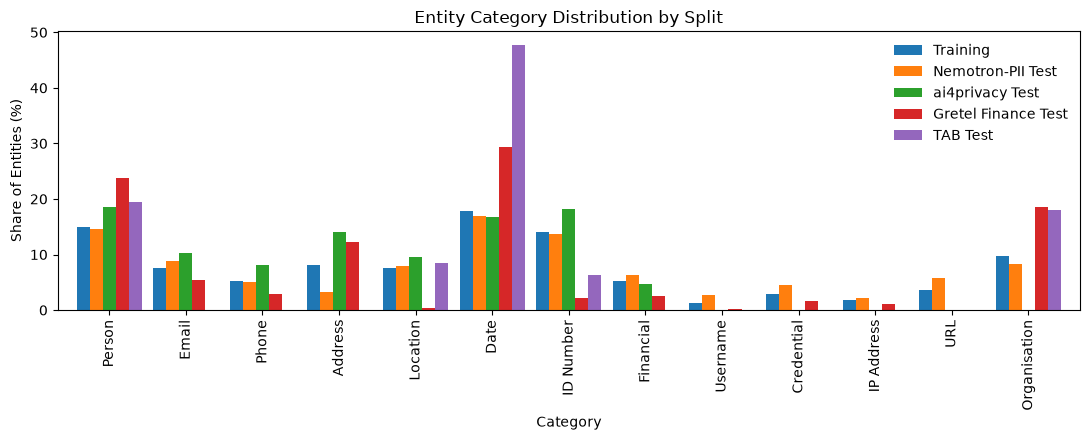

In [19]:
plot_cols = [SPLIT_NAMES[k] for k in ("train", "test_nemotron", "test_ai4privacy", "test_gretel", "test_tab")]
fig, ax = plt.subplots(figsize=(11, 4.5))
(label_df[plot_cols].div(label_df[plot_cols].sum(), axis=1) * 100).plot.bar(ax=ax, width=0.85)
ax.set_xlabel("Category")
ax.set_ylabel("Share of Entities (%)")
ax.set_title("Entity Category Distribution by Split")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_label_distribution.png", dpi=150)
plt.show()

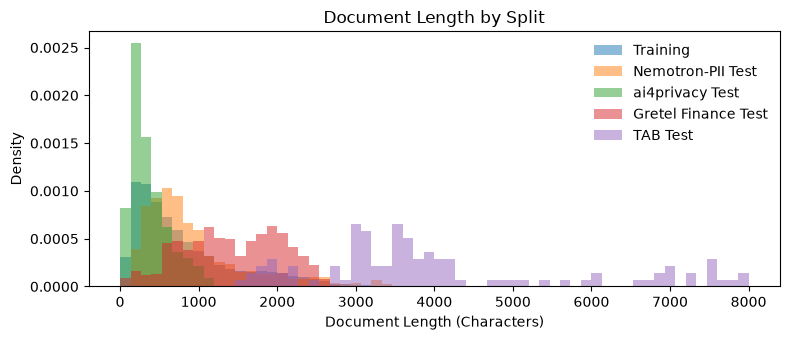

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ("train", "test_nemotron", "test_ai4privacy", "test_gretel", "test_tab"):
    ax.hist([len(r["text"]) for r in splits[name]], bins=60, alpha=0.5, label=SPLIT_NAMES[name], range=(0, 8000),
            density=True)
ax.set_xlabel("Document Length (Characters)")
ax.set_ylabel("Density")
ax.legend(frameon=False)
ax.set_title("Document Length by Split")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_doc_lengths.png", dpi=150)
plt.show()

# save the statistics above for reporting
with open(FIG_DIR / "data_stats.json", "w", encoding="utf-8") as fh:
    json.dump({"splits": stats_df.reset_index().to_dict(orient="records"),
               "training_sources": source_df.to_dict(orient="records"),
               "entities_per_category": label_df.to_dict(),
               "deduplication": dedup_df.reset_index().to_dict(orient="records"),
               "augmentation": dict(aug_counts)}, fh, indent=2)

The examples below show a harmonised training document, an augmented document and a synthetic form, with
their entities marked inline.

In [21]:
def show(rec, width=700):
    """Print a document with each entity marked inline as [text|CATEGORY]."""
    out, last = [], 0
    for s, e, lab in rec["spans"]:
        out.append(rec["text"][last:s])
        out.append(f"[{rec['text'][s:e]}|{lab}]")
        last = e
    out.append(rec["text"][last:])
    print("".join(out)[:width])


show(next(r for r in train if r["source"] == "nemotron" and len(r["spans"]) > 4 and "augmented" not in r["meta"]))
print()
show(next(r for r in train if r["meta"].get("augmented") == "australian_values" and len(r["spans"]) > 4))
print()
show(next(r for r in train if r["source"] == "forms"))

### Campus Map

**Welcome to [Edvantage|ORGANIZATION] University**

[Edvantage|ORGANIZATION] University is located at the coordinate: [34.0713, -118.2442|LOCATION]. For a detailed layout of the campus, please visit our interactive campus map at url: [https://university.edu/campus-map|URL].

**Campus Overview**

[Edvantage|ORGANIZATION] University is situated in [Shreveport|LOCATION], [LA|LOCATION], postcode: [71109|ADDRESS], country: USA. The campus spans across a beautiful landscape with various buildings, pathways, and landmarks.

**Key Locations**

- **Main Administration Building**: Located at the heart of the campus, this building houses the administrative offices and student services.


I, [Bernard J. Adams|PERSON], am applying for a loan. My date of birth is [04.02.1951|DATE]. You can reach me at [daltyn.davis@icloud.com|EMAIL]. My social security number is [263-74-6165|ID_NUMBER]. I currently reside at [133 Station Rd|ADDRESS].

Customer Information Sheet

BSB
[763-679|FINANCIA